# Breast Cancer Diagnosis with a Deep Learning MLP
**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI Machine Learning Repository
**Task:** Binary classification, malignant vs. benign tumour, from 30 numeric features computed from digitized fine-needle-aspirate images
**Model:** Multi-Layer Perceptron (Keras/TensorFlow) with basic hyperparameter tuning

### Project roadmap
| Step | Section |
|---|---|
| 1 | Dataset selection |
| 2 | EDA and preprocessing |
| 3 | Visualization (7 stages, 7 visuals) |
| 4 | Model building, feature analysis, tuning |
| 5 | Evaluation visualizations |
| 6 | Conclusion and future scope |
| 7 | Literature review and references |

## Step 1: Dataset Selection
The dataset has **569 samples and 30 numeric features** (well above the 15-feature minimum). For each of 10 cell-nucleus properties (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), three statistics are recorded: **mean**, **standard error**, and **worst** (mean of the three largest values). That gives 10 x 3 = 30 features.

It is distributed with scikit-learn (`load_breast_cancer`), which mirrors the UCI copy (Wolberg et al., 1995), so the notebook runs offline.

In [1]:
import warnings, random, os
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
                             classification_report, accuracy_score, precision_score,
                             recall_score, f1_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figures", exist_ok=True)
PAL = {"Benign": "#2a9d8f", "Malignant": "#e76f51"}

In [2]:
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
# In sklearn: target 0 = malignant, 1 = benign. Make it explicit and readable.
df["diagnosis"] = df["target"].map({0: "Malignant", 1: "Benign"})
FEATURES = list(raw.feature_names)
print("Shape:", df.shape, "| features:", len(FEATURES))
df.head()

Shape: (569, 32) | features: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


## Step 2: Data Understanding and Preprocessing
### 2.1 Exploratory Data Analysis

In [3]:
print(df[FEATURES].dtypes.value_counts(), "\n")
print("Class counts:\n", df["diagnosis"].value_counts(), "\n")
print("Class share (%):\n", (df["diagnosis"].value_counts(normalize=True)*100).round(1))
df[FEATURES].describe().T.round(3).head(12)

float64    30
Name: count, dtype: int64 

Class counts:
 diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64 

Class share (%):
 diagnosis
Benign       62.7
Malignant    37.3
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


### 2.2 Missing values, duplicates, outliers

In [4]:
# Missing values
print("Total missing cells:", int(df[FEATURES].isna().sum().sum()))
# Duplicates
print("Duplicate rows:", int(df.duplicated(subset=FEATURES).sum()))

# Outliers: IQR rule, count per feature
Q1, Q3 = df[FEATURES].quantile(.25), df[FEATURES].quantile(.75)
IQR = Q3 - Q1
out_counts = ((df[FEATURES] < Q1 - 1.5*IQR) | (df[FEATURES] > Q3 + 1.5*IQR)).sum().sort_values(ascending=False)
print("\nFeatures with most IQR outliers (1.5xIQR):")
print(out_counts.head(8))
print("Rows with >=1 outlier:", int(((df[FEATURES] < Q1 - 1.5*IQR) | (df[FEATURES] > Q3 + 1.5*IQR)).any(axis=1).sum()))

Total missing cells: 0
Duplicate rows: 0

Features with most IQR outliers (1.5xIQR):
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
dtype: int64
Rows with >=1 outlier: 171


**Decisions**
* **Missing values / duplicates:** none were found. A median `SimpleImputer` is still included in the pipeline so it is safe on future data.
* **Outliers:** the IQR rule flags a noticeable number of points, but large values (e.g., big radius or area) are mostly *real malignant tumours*, not data errors. Deleting them would remove exactly the cases we want to detect. Instead we **winsorize only extreme values (beyond 3xIQR)**, using bounds learned **from the training set only** (no leakage), then standardize.

### 2.3 Split, clean, and scale

In [5]:
X = df[FEATURES]
y = (df["diagnosis"] == "Malignant").astype(int)    # encode: 1 = Malignant (positive class), 0 = Benign

# 70 / 15 / 15 stratified split
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("Train/Val/Test:", len(X_tr), len(X_va), len(X_te))
print("Malignant share  ->", [round(v.mean(),3) for v in (y_tr, y_va, y_te)])

# Imputer + winsorize (train-only bounds) + standardize (train-only stats)
imp = SimpleImputer(strategy="median").fit(X_tr)
to_df = lambda a, idx: pd.DataFrame(a, columns=FEATURES, index=idx)
X_tr_i, X_va_i, X_te_i = to_df(imp.transform(X_tr), X_tr.index), to_df(imp.transform(X_va), X_va.index), to_df(imp.transform(X_te), X_te.index)

q1, q3 = X_tr_i.quantile(.25), X_tr_i.quantile(.75); iqr = q3 - q1
lo, hi = q1 - 3*iqr, q3 + 3*iqr
clip = lambda d: d.clip(lower=lo, upper=hi, axis=1)
X_tr_c, X_va_c, X_te_c = clip(X_tr_i), clip(X_va_i), clip(X_te_i)
print("Values clipped (train):", int((X_tr_i != X_tr_c).sum().sum()))

scaler = StandardScaler().fit(X_tr_c)
Xtr, Xva, Xte = (scaler.transform(d) for d in (X_tr_c, X_va_c, X_te_c))
ytr, yva, yte = y_tr.values, y_va.values, y_te.values
print("Train mean ~", Xtr.mean().round(3), "| std ~", Xtr.std().round(3))

Train/Val/Test: 398 85 86
Malignant share  -> [np.float64(0.372), np.float64(0.376), np.float64(0.372)]
Values clipped (train): 86
Train mean ~ 0.0 | std ~ 1.0


## Step 3: Data Visualization (7 stages)
We follow Ben Fry's seven stages of visualization: **Acquire, Parse, Filter, Mine, Represent, Refine, Interact**. Each stage is tied to a visual below. Visuals are drawn from the *raw* data (EDA), not the scaled test set.

| Stage | Meaning | Where in this project | Visual |
|---|---|---|---|
| 1. Acquire | Obtain the data | Loaded UCI dataset | V1 Class distribution |
| 2. Parse | Structure the data | Typed, labelled the 30 columns | V2 Histograms |
| 3. Filter | Remove / isolate what matters | Outlier inspection and selecting top features | V3 Boxplots |
| 4. Mine | Find patterns and relationships | Correlation analysis | V4 Correlation heatmap |
| 5. Represent | Choose a visual encoding | Pairwise relationships | V5 Pairplot |
| 6. Refine | Improve clarity and focus | Scatter with annotation and decision hint | V6 Refined scatter |
| 7. Interact | Let the user explore | Plotly interactive plot | V7 Interactive scatter |

### V1: Class distribution (Stage 1: Acquire)

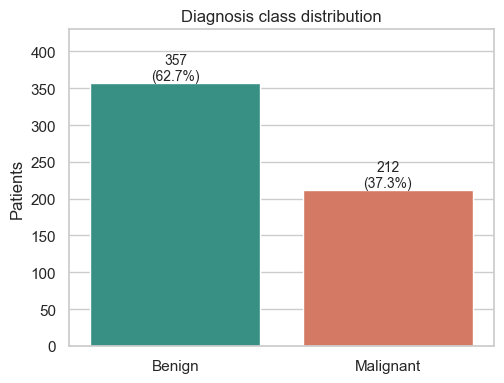

In [6]:
fig, ax = plt.subplots(figsize=(5.2,4))
order = ["Benign","Malignant"]
sns.countplot(data=df, x="diagnosis", order=order, palette=PAL, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}\n({p.get_height()/len(df)*100:.1f}%)", (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, 430); ax.set_title("Diagnosis class distribution"); ax.set_xlabel(""); ax.set_ylabel("Patients")
plt.tight_layout(); plt.savefig("figures/v1_class_distribution.png", dpi=150); plt.show()

* **What it shows:** number of benign vs. malignant samples.
* **Why:** the first thing to check after acquiring data is class balance, since it decides which metrics are trustworthy.
* **Insights:** 357 benign (62.7%) vs. 212 malignant (37.3%). Mildly imbalanced, not severe. Accuracy alone could look decent by predicting "benign" every time (62.7%), so we also use **recall, precision, F1 and AUC**, and use **stratified** splits.

### V2: Feature histograms by class (Stage 2: Parse)

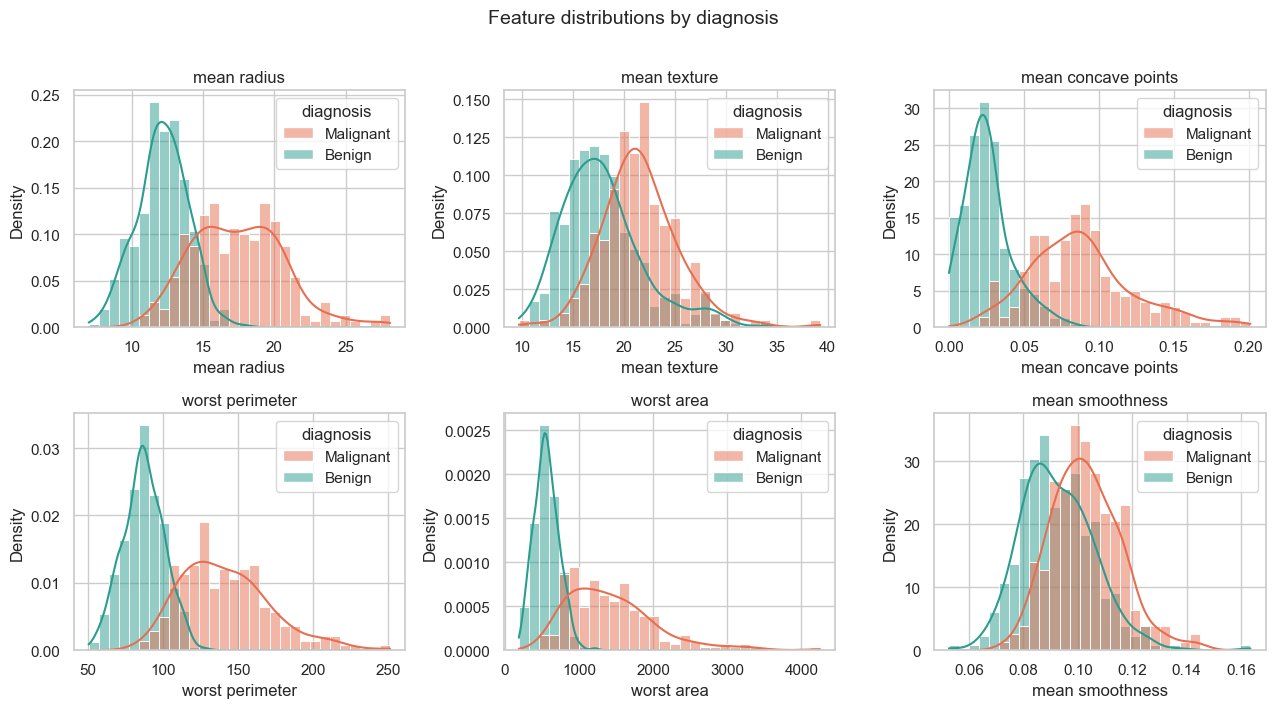

In [7]:
show = ["mean radius","mean texture","mean concave points","worst perimeter","worst area","mean smoothness"]
fig, axes = plt.subplots(2,3, figsize=(13,7))
for ax, f in zip(axes.ravel(), show):
    sns.histplot(data=df, x=f, hue="diagnosis", palette=PAL, bins=30, kde=True, stat="density", common_norm=False, ax=ax)
    ax.set_title(f)
plt.suptitle("Feature distributions by diagnosis", y=1.01, fontsize=14)
plt.tight_layout(); plt.savefig("figures/v2_histograms.png", dpi=150, bbox_inches="tight"); plt.show()

* **What it shows:** the distribution of six representative features, split by diagnosis.
* **Why:** after parsing columns into typed numeric fields, we need to see shape, skew and class overlap for each feature.
* **Insights:** size features (radius, perimeter, area) and *concave points* show a clear shift: malignant tumours are larger and more irregular. Area is right-skewed, which supports scaling. *Mean smoothness* and *mean texture* overlap heavily, so they are weaker separators on their own.

### V3: Boxplots for outlier inspection (Stage 3: Filter)

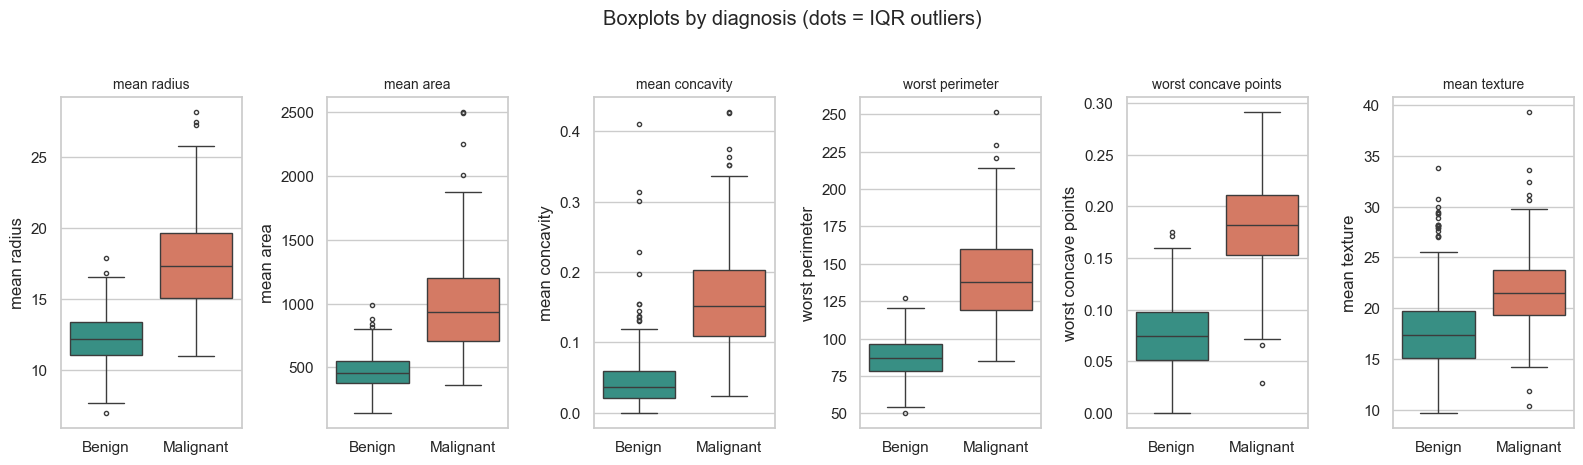

In [8]:
sel = ["mean radius","mean area","mean concavity","worst perimeter","worst concave points","mean texture"]
fig, axes = plt.subplots(1,6, figsize=(16,4.5))
for ax, f in zip(axes, sel):
    sns.boxplot(data=df, x="diagnosis", y=f, order=["Benign","Malignant"], palette=PAL, fliersize=3, ax=ax)
    ax.set_xlabel(""); ax.set_title(f, fontsize=10)
plt.suptitle("Boxplots by diagnosis (dots = IQR outliers)", y=1.03)
plt.tight_layout(); plt.savefig("figures/v3_boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

* **What it shows:** median, spread and outliers per class for key features.
* **Why:** this is the *filter* step. It tells us which points are unusual and which features carry signal before we decide how to treat outliers.
* **Insights:** medians differ strongly between classes for radius, area, concavity and the worst-case features. Mean texture separates the classes only moderately (its boxes overlap). Outliers appear in **both** classes: malignant cases at the high end of size features (radius, area, perimeter), and benign cases mainly in concavity and texture. Many of them are therefore genuine tumour variation rather than recording errors, which is why we **winsorize only extreme values** instead of dropping rows.

### V4: Correlation heatmap (Stage 4: Mine)

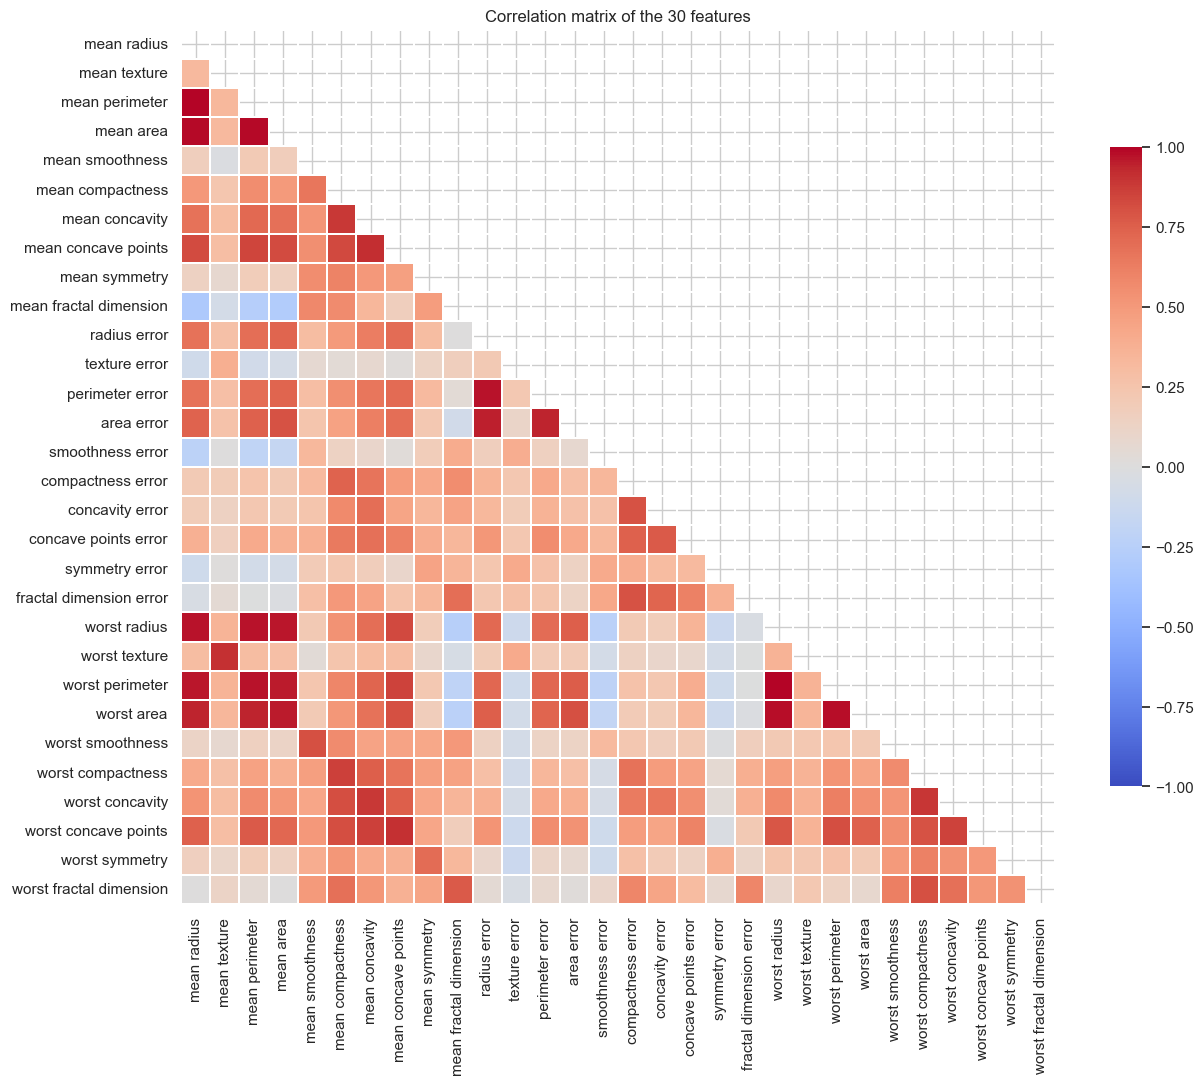

Most correlated feature pairs:
 mean radius     mean perimeter     0.998
worst radius    worst perimeter    0.994
mean radius     mean area          0.987
mean perimeter  mean area          0.987
worst radius    worst area         0.984
dtype: float64

Number of pairs with |r| > 0.9: 21


In [9]:
corr = df[FEATURES].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(13,11))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=.3, cbar_kws={"shrink":.7}, ax=ax)
ax.set_title("Correlation matrix of the 30 features")
plt.tight_layout(); plt.savefig("figures/v4_corr_heatmap.png", dpi=150); plt.show()
hp = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("Most correlated feature pairs:\n", hp.head(5).round(3))
print("\nNumber of pairs with |r| > 0.9:", int((hp.abs() > 0.9).sum()))

* **What it shows:** pairwise Pearson correlation between all 30 features.
* **Why:** mining for structure, in particular redundant features.
* **Insights:** radius, perimeter and area are almost perfectly correlated (r ~ 0.99+), and each "mean" feature is strongly tied to its "worst" version (r between 0.81 and 0.97), and 21 feature pairs have |r| > 0.9. There is heavy **multicollinearity**: the data is effectively lower-dimensional than 30 columns. This is fine for a neural network (with regularization) but would be a problem for plain linear regression coefficients. It also means feature importance scores get *shared* among correlated features.

### V5: Pairplot of top features (Stage 5: Represent)

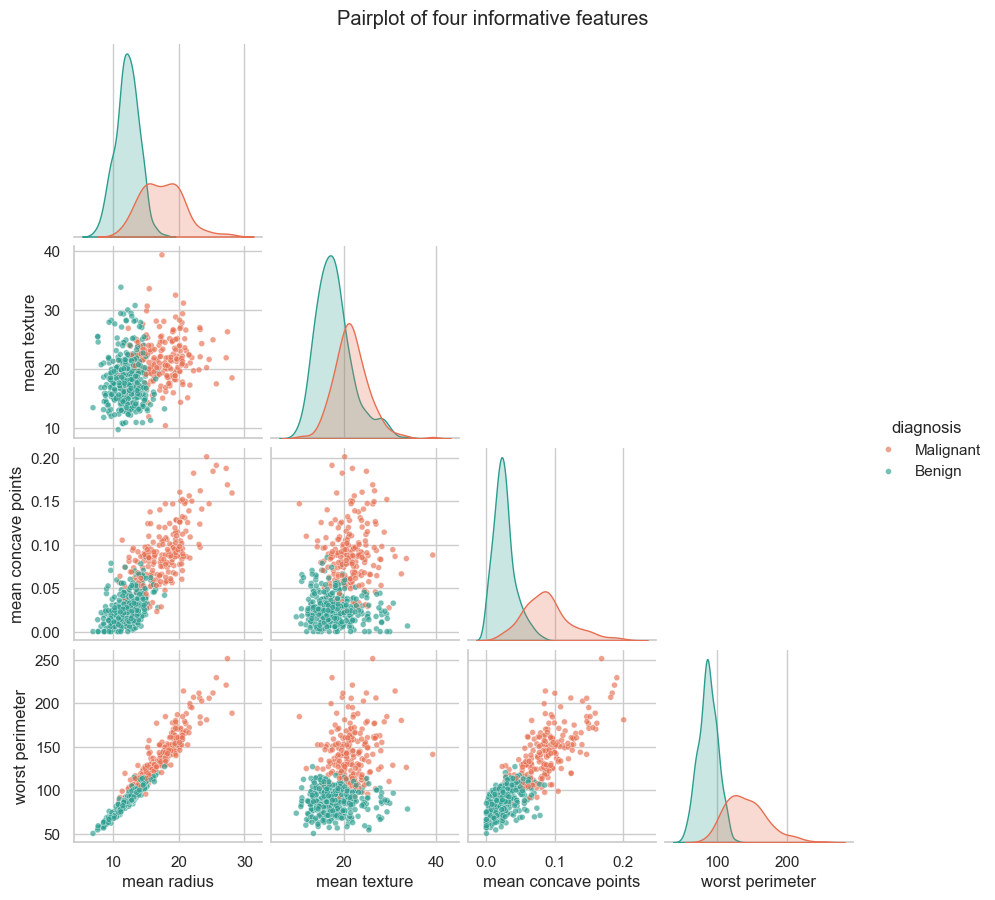

In [10]:
pp_feats = ["mean radius","mean texture","mean concave points","worst perimeter"]
g = sns.pairplot(df[pp_feats+["diagnosis"]], hue="diagnosis", palette=PAL, corner=True,
                 plot_kws={"s":18,"alpha":.65}, diag_kind="kde", height=2.2)
g.fig.suptitle("Pairplot of four informative features", y=1.02)
g.savefig("figures/v5_pairplot.png", dpi=150); plt.show()

* **What it shows:** all pairwise scatterplots plus per-class densities for four features.
* **Why:** choosing the right *representation* (scatter matrix) lets us judge separability in 2-D from many angles at once.
* **Insights:** classes form two largely distinct clusters in the size/concavity planes, so a non-linear model should separate them well. A small overlap zone near the boundary is where misclassifications are most likely. `mean texture` adds little separation.

### V6: Refined scatter with trend and annotations (Stage 6: Refine)

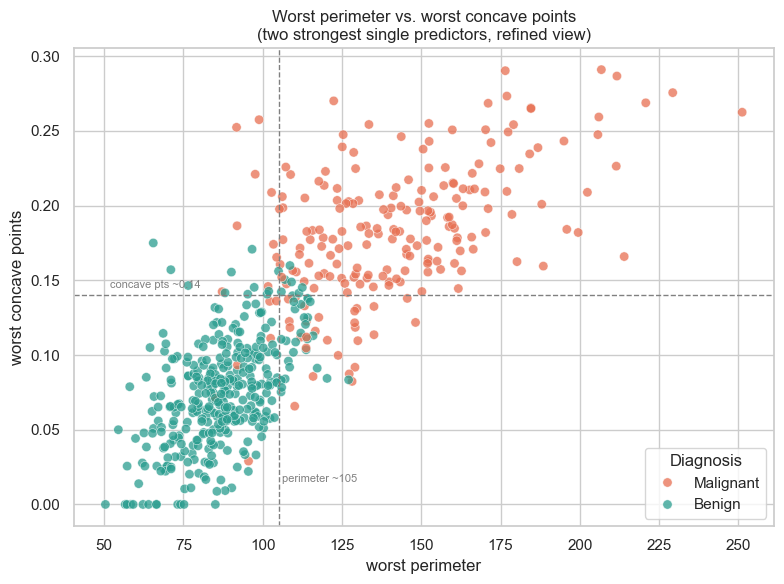

In [11]:
fig, ax = plt.subplots(figsize=(8,6))
sns.scatterplot(data=df, x="worst perimeter", y="worst concave points", hue="diagnosis", palette=PAL,
                s=45, alpha=.75, edgecolor="white", linewidth=.4, ax=ax)
ax.axvline(105, ls="--", c="grey", lw=1); ax.axhline(0.14, ls="--", c="grey", lw=1)
ax.text(106, 0.015, "perimeter ~105", fontsize=8, color="grey")
ax.text(52, 0.145, "concave pts ~0.14", fontsize=8, color="grey")
ax.set_title("Worst perimeter vs. worst concave points\n(two strongest single predictors, refined view)")
ax.legend(title="Diagnosis", loc="lower right")
plt.tight_layout(); plt.savefig("figures/v6_refined_scatter.png", dpi=150); plt.show()

* **What it shows:** the two features with highest class separation, with guide lines at approximate thresholds.
* **Why:** *refinement*: strip away clutter, add reference lines, and highlight the structure.
* **Insights:** benign cases cluster bottom-left, malignant top-right, with a thin overlapping band. The grey guide lines are approximate and eyeballed, not fitted. Even so, a few simple cut-offs already separate most cases, which is consistent with a basic linear baseline performing well later. The overlap band is the realistic source of residual errors.

### V7: Interactive scatter (Stage 7: Interact)

In [12]:
fig = px.scatter(df, x="worst perimeter", y="worst concave points", color="diagnosis",
                 color_discrete_map=PAL, size="mean area", size_max=14, opacity=.7,
                 hover_data={f: ":.2f" for f in ["mean radius","mean texture","mean concavity","worst area"]},
                 title="Interactive: hover, zoom, and click legend to filter by diagnosis")
fig.update_layout(template="plotly_white", height=520)
fig.write_html("figures/v7_interactive_scatter.html")
fig.show()

* **What it shows:** the same relationship as V6, but explorable. Marker size encodes mean area, and hovering reveals extra measurements.
* **Why:** the *interact* stage lets a clinician or analyst zoom into the borderline region and inspect individual cases. Clicking a legend entry isolates a class.
* **Insights:** zooming into the region where the two colours mix lets you inspect the borderline patients one by one, which are the cases where extra features or a second opinion would help.

## Step 4: Model Building
### 4.1 Feature analysis and feature importance
Three views: (a) correlation with the target, (b) mutual information, (c) random-forest importance. We also compute **permutation importance on the trained MLP** later.

,|corr| with target,mutual info,RF importance
worst perimeter,0.781,0.453,0.132
worst area,0.746,0.440,0.139
worst radius,0.775,0.447,0.090
mean concave points,0.768,0.436,0.102
worst concave points,0.779,0.414,0.090
mean perimeter,0.736,0.399,0.052
mean radius,0.723,0.374,0.053
mean area,0.716,0.367,0.048
area error,0.689,0.345,0.040
mean concavity,0.665,0.335,0.045


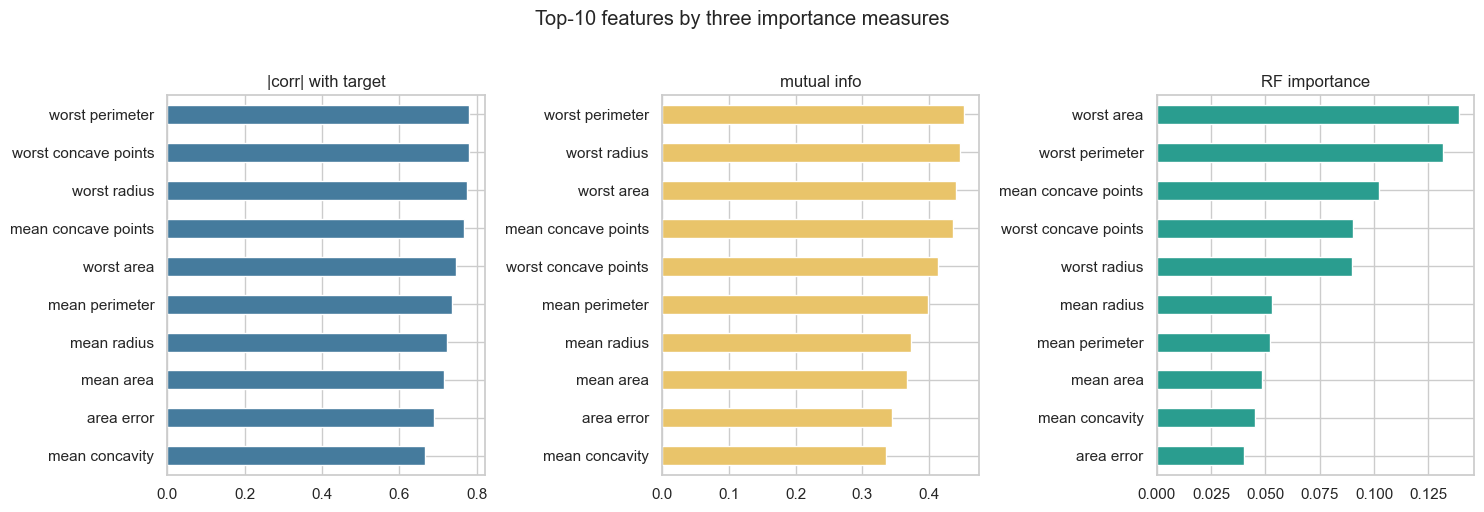

In [13]:
corr_t = X_tr_c.apply(lambda c: np.corrcoef(c, ytr)[0,1]).abs()
mi = pd.Series(mutual_info_classif(Xtr, ytr, random_state=SEED), index=FEATURES)
rf = RandomForestClassifier(n_estimators=400, random_state=SEED).fit(Xtr, ytr)
rf_imp = pd.Series(rf.feature_importances_, index=FEATURES)

imp_df = pd.DataFrame({"|corr| with target": corr_t, "mutual info": mi, "RF importance": rf_imp})
rank = imp_df.rank(ascending=False).mean(axis=1).sort_values()
top = rank.head(10).index
display(imp_df.loc[top].round(3))

fig, axes = plt.subplots(1,3, figsize=(15,5))
for ax, col, c in zip(axes, imp_df.columns, ["#457b9d","#e9c46a","#2a9d8f"]):
    imp_df[col].sort_values().tail(10).plot.barh(ax=ax, color=c); ax.set_title(col)
plt.suptitle("Top-10 features by three importance measures", y=1.02)
plt.tight_layout(); plt.savefig("figures/f1_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading the result:** all three methods agree that **worst-case size/shape features** (*worst perimeter, worst radius, worst area, worst concave points*) and *mean concave points* matter most. Because many of these are mutually correlated (V4), the importance is spread across them. No single feature is "the" driver, rather a cluster of size and concavity measurements.

### 4.2 MLP architecture and hyperparameter tuning
A compact MLP is suited to tabular data of this size: `Dense -> BatchNorm -> Dropout` blocks, sigmoid output, binary cross-entropy, Adam optimizer, early stopping on validation loss.

**Basic tuning:** a 12-point grid over hidden units, dropout and learning rate, ranked by **validation loss** (the test set stays untouched). Note that the top configurations differ by under one validation sample, so the choice is not strongly separated.

In [14]:
def build_mlp(units=32, dropout=0.2, lr=1e-3, l2=1e-4):
    reg = keras.regularizers.l2(l2)
    m = keras.Sequential([
        layers.Input(shape=(Xtr.shape[1],)),
        layers.Dense(units, activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(), layers.Dropout(dropout),
        layers.Dense(units//2, activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(), layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

def fit(m, epochs=150, verbose=0):
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    return m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=32, callbacks=[es], verbose=verbose)

import itertools
grid = list(itertools.product([16, 32, 64], [0.1, 0.3], [1e-3, 5e-3]))
rows = []
for u, d, lr in grid:
    keras.utils.set_random_seed(SEED)
    m = build_mlp(u, d, lr); h = fit(m)
    vl = min(h.history["val_loss"]); i = int(np.argmin(h.history["val_loss"]))
    rows.append(dict(units=u, dropout=d, lr=lr, val_loss=vl, val_acc=h.history["val_accuracy"][i],
                     val_auc=h.history["val_auc"][i], epochs=i+1))
tune = pd.DataFrame(rows).sort_values(["val_loss"]).reset_index(drop=True)
display(tune.round(4))
best = tune.iloc[0]; print("Best config:", dict(units=int(best.units), dropout=best.dropout, lr=best.lr))

,units,dropout,lr,val_loss,val_acc,val_auc,epochs
0,32,0.1,0.005,0.0737,0.9882,0.9976,23
1,64,0.1,0.005,0.0759,0.9882,0.9971,14
2,32,0.3,0.005,0.0781,0.9882,0.9968,26
3,64,0.1,0.001,0.0799,0.9765,0.9976,32
4,64,0.3,0.005,0.0823,0.9765,0.9971,16
5,64,0.3,0.001,0.0835,0.9765,0.9976,37
6,32,0.3,0.001,0.0850,0.9765,0.9959,53
7,16,0.3,0.001,0.0870,0.9882,0.9903,65
8,16,0.3,0.005,0.0889,0.9882,0.9826,29
9,32,0.1,0.001,0.0895,0.9647,0.9956,57


Best config: {'units': 32, 'dropout': np.float64(0.1), 'lr': np.float64(0.005)}


In [15]:
keras.utils.set_random_seed(SEED)
model = build_mlp(int(best.units), float(best.dropout), float(best.lr))
model.summary()
history = fit(model)
print("Stopped after", len(history.history["loss"]), "epochs")

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_36 (Dense)                │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,729 (6.75 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 96 (384.00 B)

Stopped after 38 epochs


### 4.3 Permutation importance on the trained MLP

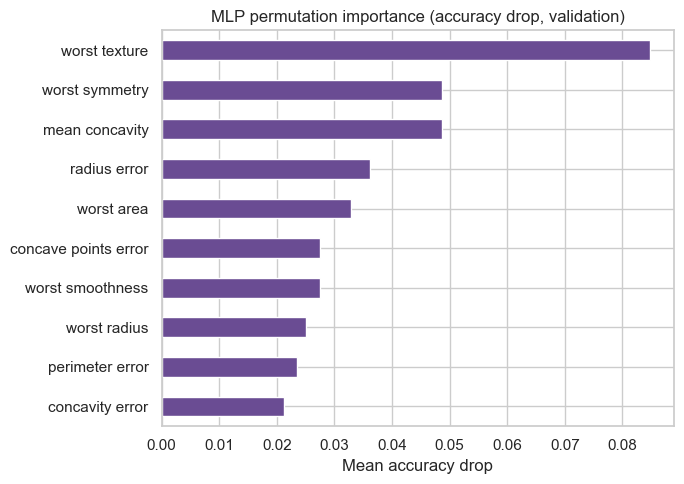

worst texture           0.0847
worst symmetry          0.0486
mean concavity          0.0486
radius error            0.0361
worst area              0.0329
concave points error    0.0275
worst smoothness        0.0275
worst radius            0.0251
dtype: float64


In [16]:
def perm_importance(model, X, y, n_rep=15, seed=SEED):
    rng = np.random.default_rng(seed)
    base = accuracy_score(y, (model.predict(X, verbose=0).ravel() > .5).astype(int))
    out = {}
    for j, f in enumerate(FEATURES):
        drops = []
        for _ in range(n_rep):
            Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
            drops.append(base - accuracy_score(y, (model.predict(Xp, verbose=0).ravel() > .5).astype(int)))
        out[f] = np.mean(drops)
    return pd.Series(out).sort_values(ascending=False)

pi = perm_importance(model, Xva, yva)   # computed on validation set
fig, ax = plt.subplots(figsize=(7,5))
pi.head(10)[::-1].plot.barh(color="#6a4c93", ax=ax)
ax.set_title("MLP permutation importance (accuracy drop, validation)"); ax.set_xlabel("Mean accuracy drop")
plt.tight_layout(); plt.savefig("figures/f2_perm_importance.png", dpi=150); plt.show()
print(pi.head(8).round(4))

**Reading the result:** permutation importance measures how much validation accuracy falls when one feature's values are shuffled. Its top features (*worst texture, worst symmetry, mean concavity*) do **not** match the filter and random-forest rankings above, and that disagreement is worth noting rather than hiding. Two likely reasons: (1) the validation set has only 85 rows, so one sample moves accuracy by about 1.2 points and the scores are noisy; (2) the many near-duplicate size features cover for each other, so shuffling any single one barely hurts, while less redundant features such as texture and symmetry show up more clearly. Treat the importance rankings as indicative, not definitive.

## Step 5: Model Evaluation Visualization
We evaluate on the held-out **test set** (never used for tuning), and compare against a Logistic Regression baseline.

In [17]:
p_te = model.predict(Xte, verbose=0).ravel(); yhat = (p_te > .5).astype(int)
lr_base = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
p_lr = lr_base.predict_proba(Xte)[:,1]

def metrics(y, p, name):
    yh = (p > .5).astype(int); fpr, tpr, _ = roc_curve(y, p)
    return dict(model=name, accuracy=accuracy_score(y,yh), precision=precision_score(y,yh),
                recall=recall_score(y,yh), f1=f1_score(y,yh), auc=auc(fpr,tpr))
res = pd.DataFrame([metrics(yte, p_te, "MLP (Keras)"), metrics(yte, p_lr, "Logistic Regression")]).set_index("model")
display(res.round(4))
print(classification_report(yte, yhat, target_names=["Benign","Malignant"], digits=3))

,accuracy,precision,recall,f1,auc
model,,,,,
MLP (Keras),0.9884,1.0000,0.9688,0.9841,0.9994
Logistic Regression,0.9651,0.9677,0.9375,0.9524,0.9988


              precision    recall  f1-score   support

      Benign      0.982     1.000     0.991        54
   Malignant      1.000     0.969     0.984        32

    accuracy                          0.988        86
   macro avg      0.991     0.984     0.987        86
weighted avg      0.989     0.988     0.988        86



### E1: Loss vs. epoch

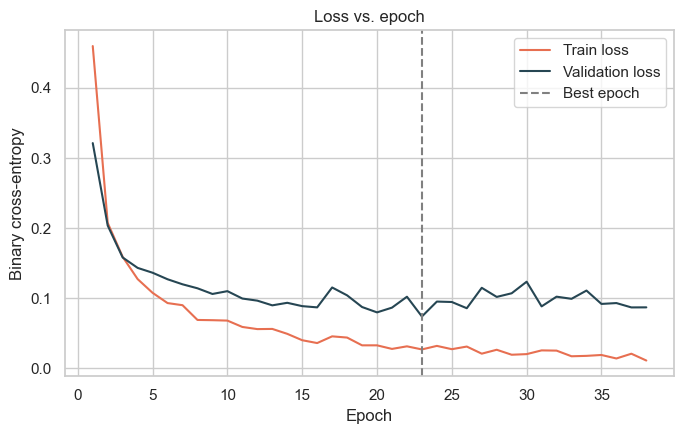

In [18]:
h = history.history; ep = np.arange(1, len(h["loss"])+1)
fig, ax = plt.subplots(figsize=(7,4.5))
ax.plot(ep, h["loss"], label="Train loss", c="#e76f51"); ax.plot(ep, h["val_loss"], label="Validation loss", c="#264653")
ax.axvline(int(np.argmin(h["val_loss"]))+1, ls="--", c="grey", label="Best epoch")
ax.set_xlabel("Epoch"); ax.set_ylabel("Binary cross-entropy"); ax.set_title("Loss vs. epoch"); ax.legend()
plt.tight_layout(); plt.savefig("figures/e1_loss.png", dpi=150); plt.show()

**Explanation:** both curves fall quickly in the first ~5 epochs. After that, training loss keeps dropping to about 0.01 while validation loss levels off near 0.08-0.10 and bounces around, so a **gap opens: mild overfitting** (expected with ~1,700 parameters and 398 training rows). Early stopping at epoch 23 (dashed line, lowest validation loss) restored those weights, which limits the damage.

### E2: Accuracy vs. epoch

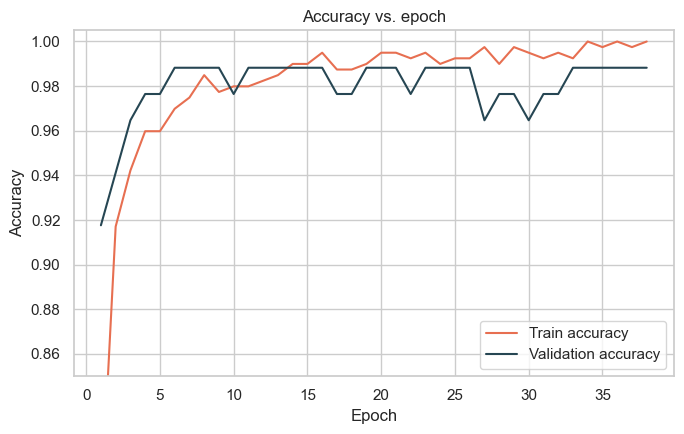

In [19]:
fig, ax = plt.subplots(figsize=(7,4.5))
ax.plot(ep, h["accuracy"], label="Train accuracy", c="#e76f51"); ax.plot(ep, h["val_accuracy"], label="Validation accuracy", c="#264653")
ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy"); ax.set_ylim(0.85,1.005); ax.set_title("Accuracy vs. epoch"); ax.legend()
plt.tight_layout(); plt.savefig("figures/e2_accuracy.png", dpi=150); plt.show()

**Explanation:** accuracy passes 96% within about 5 epochs. Training accuracy creeps toward 100%, while validation accuracy plateaus around 97-99%, which agrees with the small overfitting gap seen in the loss chart. The validation set has only 85 samples, so each sample is about 1.2 percentage points and the curve moves in steps.

### E3: Confusion matrix

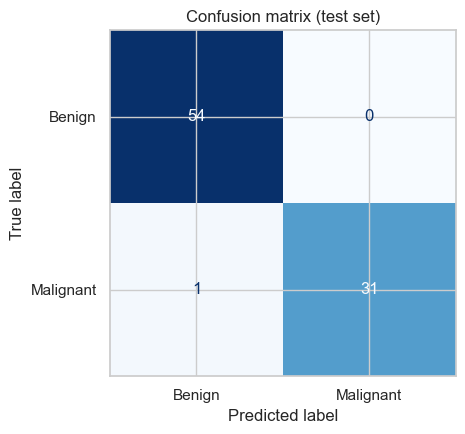

TN=54 FP=0 FN=1 TP=31


In [20]:
cm = confusion_matrix(yte, yhat)
fig, ax = plt.subplots(figsize=(5,4.5))
ConfusionMatrixDisplay(cm, display_labels=["Benign","Malignant"]).plot(cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion matrix (test set)")
plt.tight_layout(); plt.savefig("figures/e3_confusion.png", dpi=150); plt.show()
tn, fp, fn, tp = cm.ravel(); print(f"TN={tn} FP={fp} FN={fn} TP={tp}")

**Explanation:** on the 86 test samples the model made **0 false positives and 1 false negative** (TN=54, FP=0, FN=1, TP=31). The diagonal holds correct predictions. The off-diagonal cells are the costly part: **false negatives** (malignant predicted benign) are clinically more serious than **false positives** (extra follow-up testing). In a screening setting we would lower the decision threshold to push recall higher, accepting a few more false alarms.

### E4: ROC curve and AUC

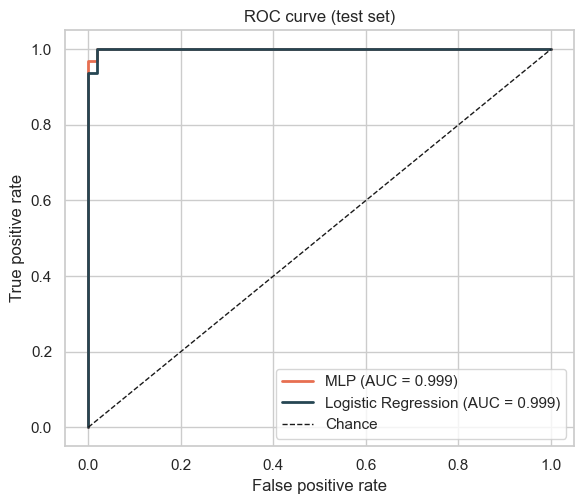

In [21]:
fig, ax = plt.subplots(figsize=(6,5.2))
for p, name, c in [(p_te,"MLP","#e76f51"), (p_lr,"Logistic Regression","#264653")]:
    fpr, tpr, _ = roc_curve(yte, p); ax.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr,tpr):.3f})", c=c, lw=2)
ax.plot([0,1],[0,1],"k--",lw=1,label="Chance"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curve (test set)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/e4_roc.png", dpi=150); plt.show()

**Explanation:** the curve hugging the top-left corner means high recall at very low false-positive rates. The MLP's **AUC is 0.9994** and the logistic regression's is 0.9988, so the two rank cases almost equally well, which fits the near-linear separability seen in V5/V6. Their accuracies differ more (98.8% vs 96.5%), but that is only 2 test samples out of 86, so it should not be read as a reliable win for the deep model.

### E5: Prediction-error distribution (classification analogue of an error plot)

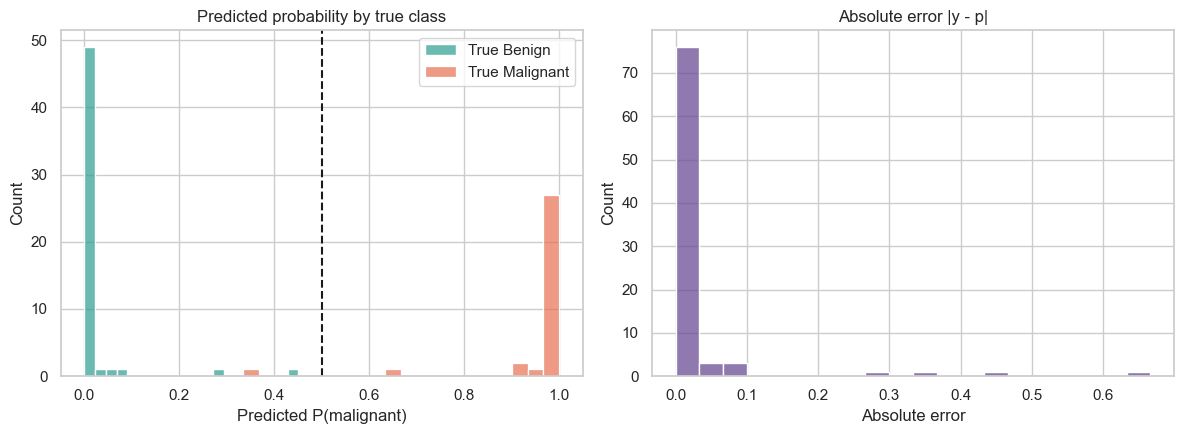

Mean absolute error: 0.0266 | samples with error > 0.5: 1


In [22]:
fig, axes = plt.subplots(1,2, figsize=(12,4.5))
for lab, name in [(0,"Benign"),(1,"Malignant")]:
    sns.histplot(p_te[yte==lab], bins=20, color=PAL[name], alpha=.7, label=f"True {name}", ax=axes[0])
axes[0].axvline(.5, c="k", ls="--"); axes[0].set_xlabel("Predicted P(malignant)"); axes[0].set_title("Predicted probability by true class"); axes[0].legend()
err = np.abs(yte - p_te)
sns.histplot(err, bins=20, color="#6a4c93", ax=axes[1]); axes[1].set_title("Absolute error |y - p|"); axes[1].set_xlabel("Absolute error")
plt.tight_layout(); plt.savefig("figures/e5_error_distribution.png", dpi=150); plt.show()
print("Mean absolute error:", err.mean().round(4), "| samples with error > 0.5:", int((err>.5).sum()))

**Explanation:** predicted probabilities pile up near 0 and 1, so the model is confident and mostly correct. The mean absolute error is 0.027 and only **one** test sample has error above 0.5: a malignant tumour given P(malignant) of about 0.35, i.e. the single false negative. A few other cases sit in the 0.3-0.65 zone but fall on the right side of the threshold. These are the borderline cases anticipated in V6/V7.

## Step 6: Conclusion and Future Scope
### What we learned
* The dataset is clean (no missing values or duplicates) and mildly imbalanced (62.7% benign / 37.3% malignant).
* **Size and concavity measurements**, especially the *worst* values (perimeter, radius, area, concave points), best separate malignant from benign tumours.
* The 30 features are highly redundant (radius, perimeter and area correlate above 0.98), so the information is effectively low-dimensional.

### Model performance
A small MLP (32-16-1, batch normalization, dropout 0.1, L2, Adam at lr 0.005), tuned on the validation set, reached **98.8% test accuracy, precision 1.00, recall 0.969, F1 0.984 and AUC 0.9994** (1 false negative, 0 false positives out of 86). The Logistic Regression baseline scored 96.5% accuracy and AUC 0.9988, so the deep model is slightly ahead on accuracy but essentially tied on AUC. With 86 test samples this gap is within noise, and it suggests the problem is close to linearly separable and that depth adds limited value here. These are single-split results and should be confirmed with cross-validation.

### Challenges
* **Tiny dataset:** the test set has only 86 samples (validation 85), so one error changes accuracy by about 1.2 points. Results have wide confidence intervals.
* **Mild overfitting:** training loss kept falling while validation loss plateaued; early stopping and dropout limited but did not remove it.
* **Outliers vs. real signal:** the large values are genuine malignant cases, so removing them would hurt. We used conservative winsorization.
* **Multicollinearity** makes feature importance ambiguous: filter/random-forest rankings favour worst-case size features, while MLP permutation importance on the small validation set highlighted different features.
* **Clinical cost asymmetry:** a missed cancer is worse than a false alarm, so accuracy alone is not the right target.

### Future scope
* Use **repeated stratified k-fold cross-validation** and report confidence intervals.
* Tune the **decision threshold** for a target recall (e.g., >= 99%), and add **probability calibration**.
* Use **Bayesian optimization or Keras Tuner** for broader hyperparameter search, and compare with gradient boosting (XGBoost/LightGBM).
* Add **explainability** (SHAP, LIME) for clinical trust.
* Train a **CNN directly on the cytology images** instead of hand-crafted features, and add patient metadata (age, family history).
* Validate on **external hospital data** to check for dataset shift before any clinical use. This project is educational and not a diagnostic tool.

## Step 7: Literature Review and References
**Short review.** Mangasarian, Street and Wolberg showed that cell-nucleus features extracted from fine-needle-aspirate images can discriminate benign from malignant tumours using linear programming and simple classifiers, with accuracy above 95%. Subsequent work applied SVMs, random forests and neural networks to the same data with similar results, showing the task is well-suited to both classical and deep models. Regularization techniques such as dropout and batch normalization, together with early stopping, are standard tools to prevent overfitting on small tabular datasets. Fry's seven-stage model provides the framework used for the visualization workflow here.

**References (IEEE style)**
1. W. H. Wolberg, W. N. Street, and O. L. Mangasarian, "Breast Cancer Wisconsin (Diagnostic)," UCI Machine Learning Repository, 1995. [Online]. Available: https://archive.ics.uci.edu/dataset/17
2. W. N. Street, W. H. Wolberg, and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis," in *Proc. IS&T/SPIE Int. Symp. Electronic Imaging: Science and Technology*, vol. 1905, 1993, pp. 861-870.
3. N. Srivastava, G. Hinton, A. Krizhevsky, I. Sutskever, and R. Salakhutdinov, "Dropout: A simple way to prevent neural networks from overfitting," *J. Mach. Learn. Res.*, vol. 15, pp. 1929-1958, 2014.
4. S. Ioffe and C. Szegedy, "Batch normalization: Accelerating deep network training by reducing internal covariate shift," in *Proc. 32nd Int. Conf. Machine Learning (ICML)*, 2015, pp. 448-456.
5. D. P. Kingma and J. Ba, "Adam: A method for stochastic optimization," in *Proc. Int. Conf. Learning Representations (ICLR)*, 2015.
6. B. Fry, *Visualizing Data: Exploring and Explaining Data with the Processing Environment*. Sebastopol, CA, USA: O'Reilly Media, 2007.
7. F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825-2830, 2011.
8. M. Abadi *et al.*, "TensorFlow: Large-scale machine learning on heterogeneous systems," 2015. [Online]. Available: https://www.tensorflow.org